# Sortability across all benchmark and evaluation conditions

Varsortability and R²-sortability for every stored dataset instance: all 36 benchmark conditions and all six held-out evaluation families. Associations with F1 use dataset-level averages over model seeds.


In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("benchmark/sortability")
from scipy.stats import spearmanr
from statistical_methods import holm
from varsortability import calculate_varsortability


In [2]:
from condition_data import load_sample, sample_path, load_results


def sortability(frame, study):
    rows = []
    for family, seed in (
        frame[["dataset", "dataset_seed"]].drop_duplicates().itertuples(index=False, name=None)
    ):
        path = sample_path({"tuned_untuned": "evaluation"}.get(study, study), family)
        with load_sample(study, family, int(seed)) as data:
            raw = "X_raw" in data.files
            result = calculate_varsortability(data["X_raw"] if raw else data["X"], data["true_adj"])
            if not raw:
                for key in (
                    "varsortability",
                    "n_ordered_variance_paths",
                    "n_tied_variance_paths",
                ):
                    result[key] = np.nan
        rows.append(
            dict(
                dataset=family,
                dataset_seed=seed,
                study=study,
                raw_variance_available=raw,
                sample_path=str(path.relative_to(ROOT)),
                **result,
            )
        )
    return pd.DataFrame(rows)




In [3]:
output = ROOT / "results/benchmark/sortability"
output.mkdir(parents=True, exist_ok=True)
sources = th.load_aligned_sources()
frames = [("benchmark", th.prepare_metrics(load_results("benchmark"))), ("tuned_untuned", sources["complete"])]
sort_tables, correlations = [], []
for study, frame in frames:
    values = sortability(frame, study)
    sort_tables.append(values)
    arms = [("untuned", frame)] if study == "benchmark" else frame.groupby("arm", observed=True)
    for arm, arm_frame in arms:
        blocks = th.seed_means(arm_frame, "f1").merge(values, on=["dataset", "dataset_seed"])
        for (family, model), group in blocks.groupby(["dataset", "model"], observed=True):
            for score in ("r2_sortability", "varsortability"):
                valid = group[["f1", score]].dropna()
                if len(valid) < 3:
                    continue
                result = None if valid.nunique().min() < 2 else spearmanr(valid[score], valid.f1)
                correlations.append(dict(study=study, arm=arm, dataset=family, model=model,
                    sortability=score, n_pairs=len(valid), rho=np.nan if result is None else result.statistic,
                    pvalue=np.nan if result is None else result.pvalue,
                    status="constant_or_insufficient" if result is None else "estimated"))
sortability_all = pd.concat(sort_tables, ignore_index=True)
corr = pd.DataFrame(correlations)
corr["pvalue_holm"] = np.nan
valid = corr.pvalue.notna()
corr.loc[valid, "pvalue_holm"] = corr.loc[valid].groupby(["study", "arm", "sortability"]).pvalue.transform(holm)
display(sortability_all)
display(corr)


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,11,benchmark,True,datasets/benchmark/10nodes_EB_obsconf0_latconf...,0.878788,0.696970,33,29,0,23,0,10,2000
1,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,19,benchmark,True,datasets/benchmark/10nodes_EB_obsconf0_latconf...,1.000000,0.500000,14,14,0,7,0,10,2000
2,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,27,benchmark,True,datasets/benchmark/10nodes_EB_obsconf0_latconf...,1.000000,0.894737,19,19,0,17,0,10,2000
3,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,30,benchmark,True,datasets/benchmark/10nodes_EB_obsconf0_latconf...,0.923077,0.692308,26,24,0,18,0,10,2000
4,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,42,benchmark,True,datasets/benchmark/10nodes_EB_obsconf0_latconf...,1.000000,0.869565,23,23,0,20,0,10,2000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
625,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,222,tuned_untuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.234694,0.193878,98,23,0,19,0,20,2000
626,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,237,tuned_untuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.421687,0.253012,83,35,0,21,0,20,2000
627,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,308,tuned_untuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.623762,0.584158,101,63,0,59,0,20,2000
628,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,402,tuned_untuned,True,datasets/tuned/20nodes_ModOncogene_obsconf0_la...,0.777778,0.611111,54,42,0,33,0,20,2000


,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
0,benchmark,untuned,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,AVICI,r2_sortability,15,0.071556,0.799945,estimated,1.0
1,benchmark,untuned,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,AVICI,varsortability,15,0.358279,0.189765,estimated,1.0
2,benchmark,untuned,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Linear,r2_sortability,15,-0.641645,0.009924,estimated,1.0
3,benchmark,untuned,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Linear,varsortability,15,-0.373030,0.170860,estimated,1.0
4,benchmark,untuned,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Nonlinear,r2_sortability,15,-0.032143,0.909462,estimated,1.0
...,...,...,...,...,...,...,...,...,...,...
1379,tuned_untuned,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,PC,varsortability,15,0.216265,0.438839,estimated,1.0
1380,tuned_untuned,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,Random,r2_sortability,15,-0.214286,0.443141,estimated,1.0
1381,tuned_untuned,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,Random,varsortability,15,-0.003571,0.989921,estimated,1.0
1382,tuned_untuned,untuned,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,SCORE,r2_sortability,15,-0.396429,0.143495,estimated,1.0


## Family summaries


In [4]:
sortability_all["n_nodes"] = sortability_all.dataset.str.extract(r"^(\d+)nodes").astype(int)
family_summary = sortability_all.groupby(["study", "dataset", "n_nodes"]).agg(
    dataset_instances=("dataset_seed", "nunique"), varsortability_mean=("varsortability", "mean"),
    varsortability_std=("varsortability", "std"), r2_sortability_mean=("r2_sortability", "mean"),
    r2_sortability_std=("r2_sortability", "std")).reset_index()
display(family_summary)


,study,dataset,n_nodes,dataset_instances,varsortability_mean,varsortability_std,r2_sortability_mean,r2_sortability_std
0,benchmark,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10,15,0.970212,0.037060,0.750205,0.154758
1,benchmark,10nodes_EB_obsconf0_latconf0_Gaussian_Mixed,10,15,0.860045,0.101245,0.496597,0.212774
2,benchmark,10nodes_EB_obsconf0_latconf0_HighGaussian_Linear,10,15,0.955838,0.051057,0.738237,0.170792
3,benchmark,10nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,10,15,0.717002,0.176881,0.350600,0.144961
4,benchmark,10nodes_EB_obsconf0_latconf0_NonGaussian_Linear,10,15,0.885421,0.106224,0.664557,0.229735
5,benchmark,10nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,10,15,0.374412,0.199530,0.493439,0.176658
6,benchmark,10nodes_EB_obsconf0_latconf3_Gaussian_Linear,10,15,0.976055,0.028892,0.716214,0.181907
7,benchmark,10nodes_EB_obsconf2_latconf2_Gaussian_Linear,10,15,0.963205,0.060288,0.779599,0.177673
8,benchmark,10nodes_EB_obsconf3_latconf0_Gaussian_Linear,10,15,0.971515,0.049515,0.742311,0.161609
9,benchmark,15nodes_EB_obsconf0_latconf0_Gaussian_Linear,15,15,0.982660,0.016322,0.848588,0.106791


## All benchmark datasets


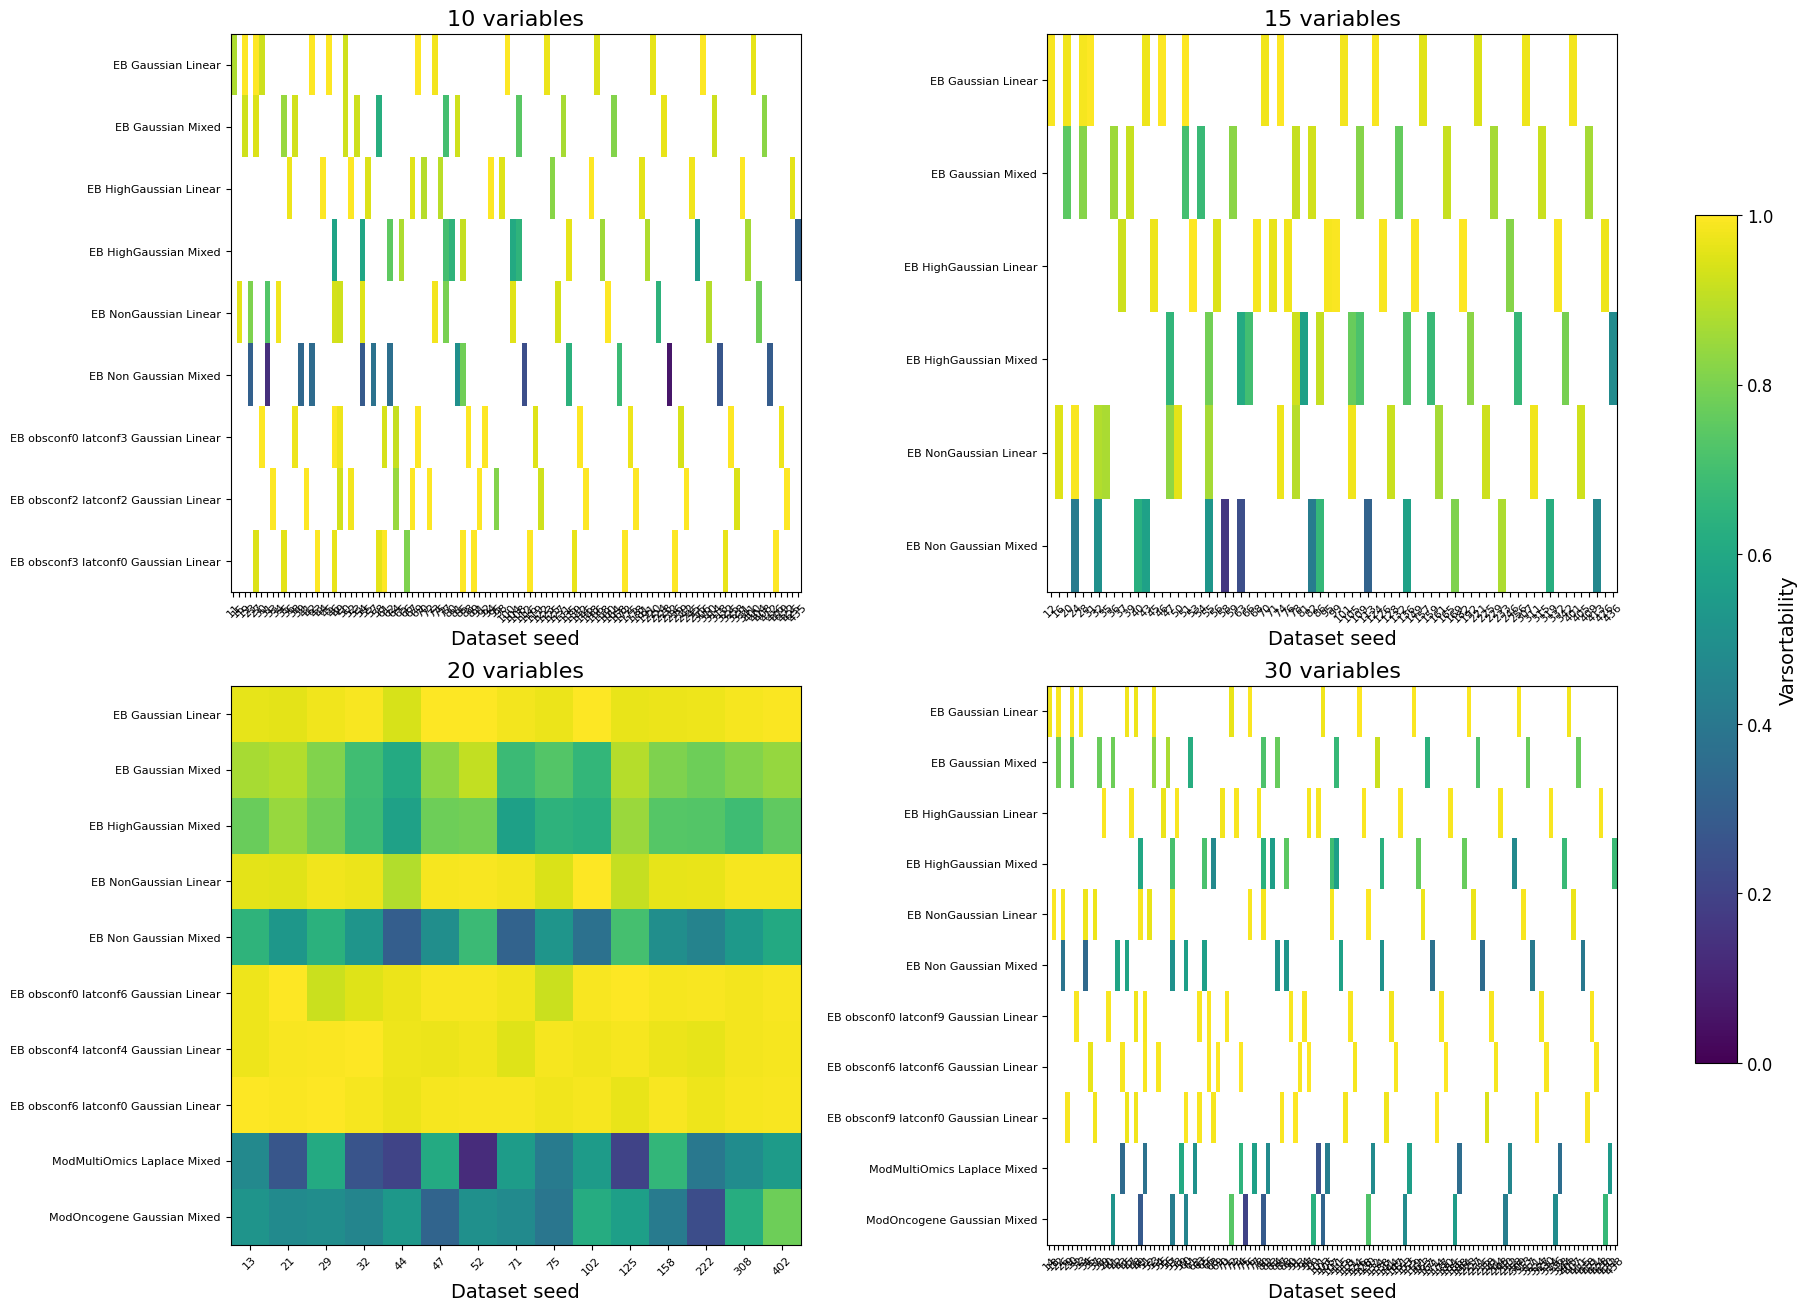

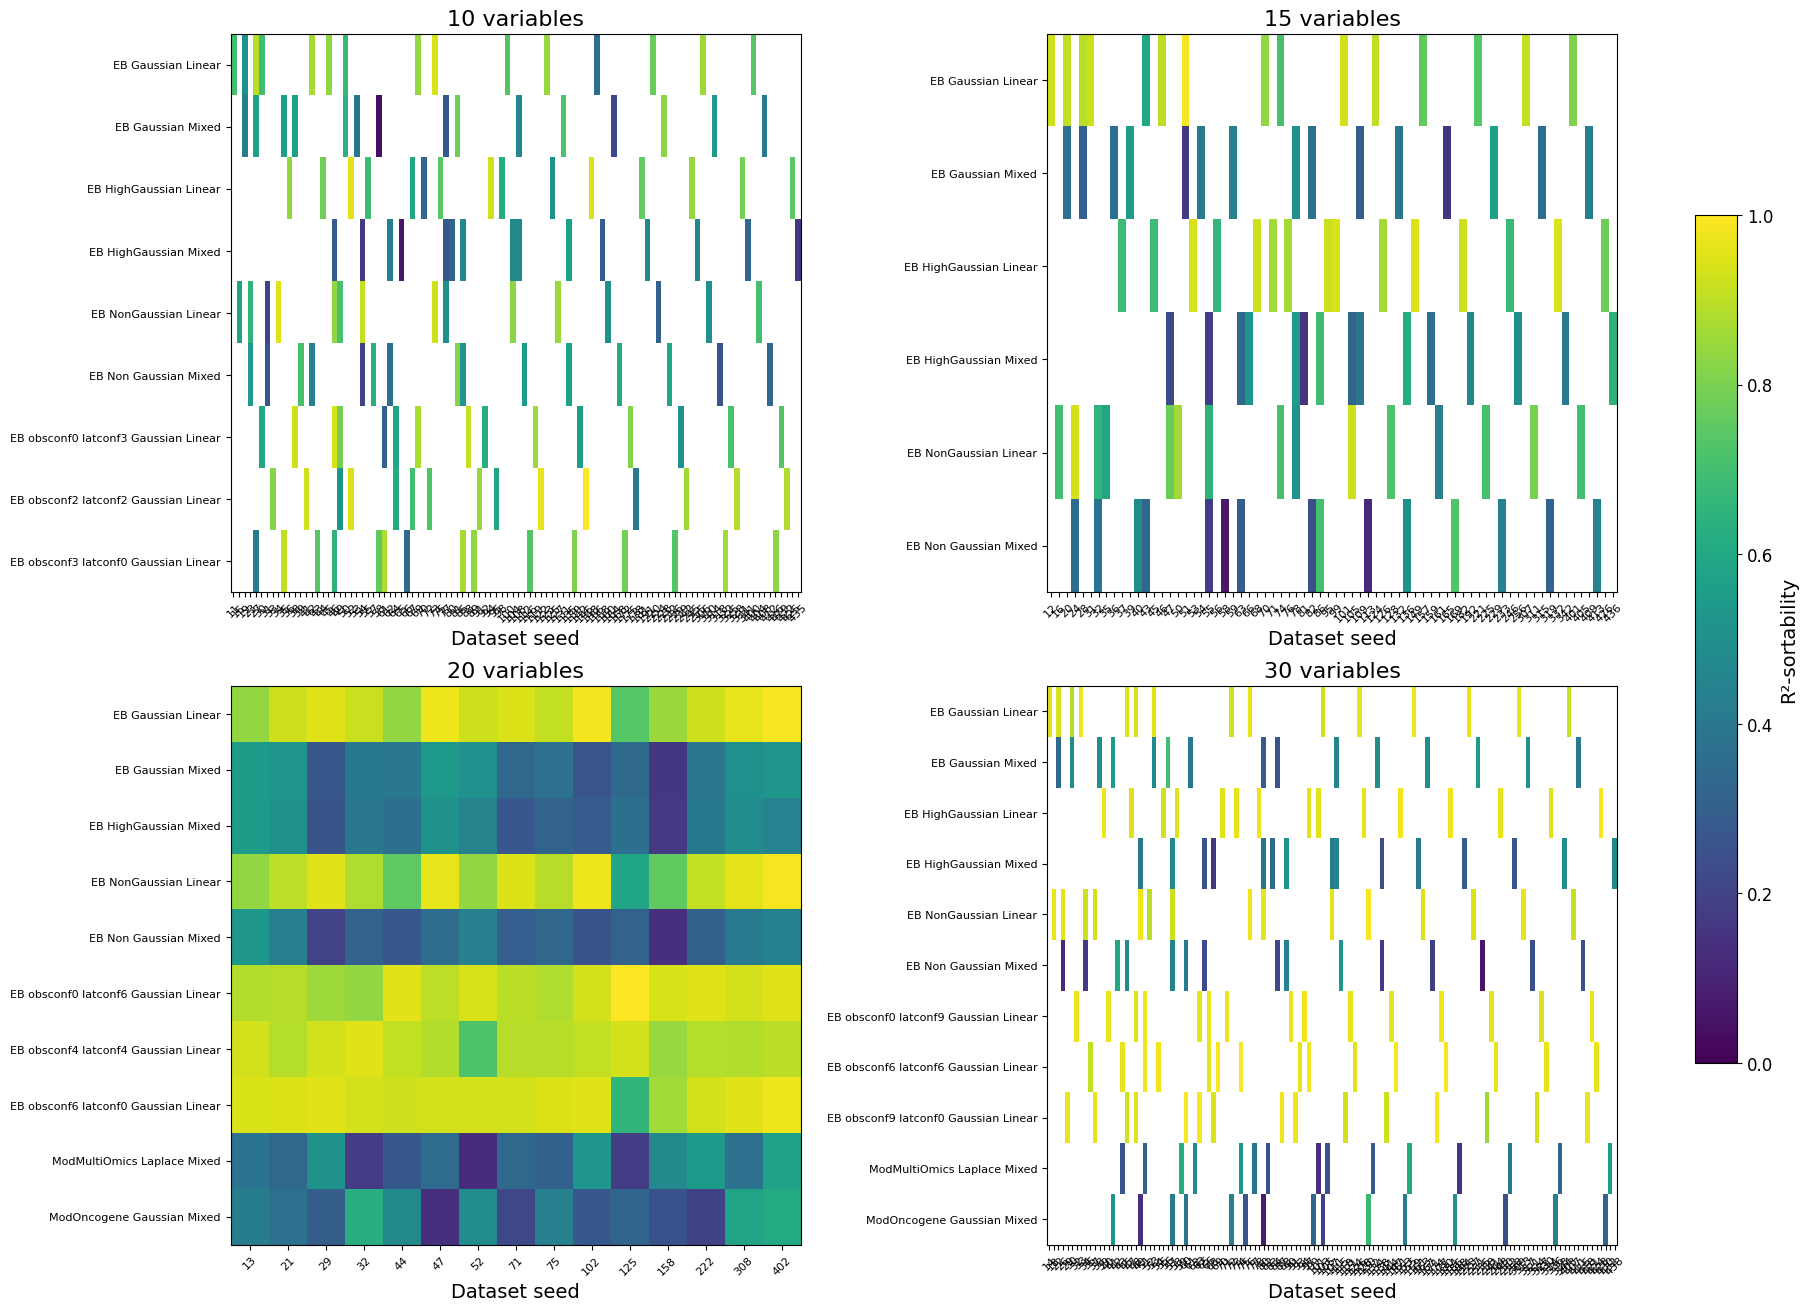

In [5]:
for score, label in [("varsortability", "Varsortability"), ("r2_sortability", "R²-sortability")]:
    benchmark = sortability_all.loc[sortability_all.study.eq("benchmark")]
    fig, axes = plt.subplots(2, 2, figsize=(18, 13), constrained_layout=True)
    for ax, size in zip(axes.flat, sorted(benchmark.n_nodes.unique())):
        part = benchmark.loc[benchmark.n_nodes.eq(size)]
        values = part.pivot(index="dataset", columns="dataset_seed", values=score)
        im = ax.imshow(np.ma.masked_invalid(values.to_numpy(float)), vmin=0, vmax=1, cmap="viridis", aspect="auto")
        labels = [name.split("nodes_", 1)[1].replace("_obsconf0_latconf0", "").replace("_", " ") for name in values.index]
        ax.set_yticks(range(len(values)), labels, fontsize=8)
        ax.set_xticks(range(len(values.columns)), values.columns, rotation=45, fontsize=8)
        ax.set_title(f"{int(size)} variables")
        ax.set_xlabel("Dataset seed")
    fig.colorbar(im, ax=axes.ravel().tolist(), label=label, shrink=.7)
    fig.savefig(output / f"benchmark_all_conditions_{score}.pdf", bbox_inches="tight")
    display(fig)
    plt.close(fig)
